# Analisis Spasial Penggunaan Lahan (LULC) dan Kebijakan Tata Ruang Jawa Timur Berbasis Citra Satelit Sentinel-2A dan Multi-Model Machine Learning

>**Aplikasi Web GIS Interaktif (Streamlit Live):**  
> Dashboard geospasial Sentinel-2A dan evaluasi 4 model Machine Learning dapat diakses secara daring pada:  
>**[https://dy-nm-psd.streamlit.app/](https://dy-nm-psd.streamlit.app/)**

> **Tugas / Ujian Tengah Semester (UTS): Sistem Informasi Geografis (SIG)**  
> **Topik:** Analisis Spasial Penggunaan Lahan (*Land Use / Land Cover - LULC*) & Evaluasi Kebijakan Tata Ruang Berbasis Citra Satelit Multispektral Sentinel-2A  
> **Wilayah Kajian:** Provinsi Jawa Timur (Koordinat $110.89^\circ - 116.27^\circ$ BT, $5.04^\circ - 8.78^\circ$ LS)  
> **Standar Rujukan:** SNI 7645-1:2014 (Klasifikasi Penutup Lahan Indonesia) & Ditjen PKTL KLHK  

---

## Ringkasan Eksekutif Proyek
Proyek ini mengintegrasikan **Penginderaan Jauh (Remote Sensing)**, **Sistem Informasi Geografis (SIG)**, dan **Machine Learning** untuk melakukan klasifikasi tutupan lahan multikelas di Provinsi Jawa Timur. Berbeda dari klasifikasi biner sederhana (sawah vs non-sawah), proyek ini memetakan **6 kelas tutupan lahan strategis** yang memiliki implikasi langsung terhadap kebijakan tata ruang daerah, ketahanan pangan, dan konservasi ekosistem pesisir serta perairan pedalaman.

Alur analisis dirancang secara komprehensif mencakup:
1. **Data Understanding & Kebijakan Tata Ruang:** Landasan hukum LP2B (UU No. 41/2009), RTRW Jatim 2023–2043 (Perda Jatim No. 10/2023), konservasi mangrove, dan perlindungan danau vulkanik (ranu-ranu).
2. **Koleksi Data Citra Satelit via openEO Copernicus (CDSE):** Eksplorasi karakteristik optik dan inframerah instrumen Sentinel-2A MSI (*Multi-Spectral Instrument*) Level-2A BOA (*Bottom-of-Atmosphere*).
3. **Data Ground Truth Terverifikasi (GeoJSON & QGIS Shapefile ZIP):** 300 petak sampel ground-truth valid berbasis titik landmark publik OpenStreetMap (OSM) dan geodatabase spasial Jawa Timur lengkap dengan berkas penataan gaya QGIS (`.qml`).
4. **Ekstraksi Fitur Spektral:** Perhitungan nilai reflektansi 6 band inti dan 6 indeks spektral matematis (**NDVI, MNDWI, NDBI, BSI, SAVI, NDMI**).
5. **Eksperimen & Komparasi Multi-Model ML:** Membandingkan algoritma **Random Forest**, **XGBoost (Extreme Gradient Boosting)**, **Support Vector Machine (SVM)**, dan **Gradient Boosting** untuk menemukan akurasi tertinggi.
6. **Prediksi Citra Satelit & Ekspor GeoTIFF QGIS Ready:** Menghasilkan raster GeoTIFF klasifikasi 6 kelas tutupan lahan dan citra komposit Sentinel-2A multi-band.
7. **Visualisasi Peta Interaktif SIG (Folium & WMS Google Satellite):** Menyajikan kontrol layer interaktif per kelas tutupan lahan, layer prediksi ML, dan overlay raster klasifikasi.
8. **Rekomendasi Kebijakan Spasial:** Sintesis temuan machine learning terhadap zonasi tata ruang Jawa Timur.


---
## Bab 1: Data Understanding & Landasan Kebijakan Tata Ruang Indonesia

### 1.1 Tujuan Analisis Land Use & Land Cover (LULC)
Klasifikasi Penggunaan Lahan (*Land Use*) dan Tutupan Lahan (*Land Cover*) berbasis citra satelit penginderaan jauh bertujuan untuk:
1. **Monitoring Alih Fungsi Lahan Pertanian ke Non-Pertanian:** Mendeteksi laju penyusutan lahan sawah produktif akibat ekspansi kawasan industri dan permukiman (*urban sprawl*) di kawasan aglomerasi Gerbangkertosusila (Gresik, Bangkalan, Mojokerto, Surabaya, Sidoarjo, Lamongan).
2. **Perlindungan Lahan Pertanian Pangan Berkelanjutan (LP2B):** Menyediakan basis data spasial audit pemenuhan amanat **Undang-Undang No. 41 Tahun 2009** tentang Perlindungan Lahan Pertanian Pangan Berkelanjutan dan **Perda Provinsi Jawa Timur No. 10 Tahun 2023** tentang Rencana Tata Ruang Wilayah (RTRW) Provinsi Jawa Timur Tahun 2023–2043.
3. **Konservasi Ekosistem Pesisir & Mangrove:** Memetakan sabuk hijau (*green belt*) mangrove di sepanjang pesisir Pantai Utara (Pantura) dan Pantai Timur Surabaya (Pamurbaya) guna mencegah abrasi, intrusi air laut, serta mendukung mitigasi perubahan iklim melalui penyerapan karbon biru (*blue carbon*).
4. **Preservasi Sumber Daya Air & Ranu-Ranu:** Memantau keterjagaan danau vulkanik (*maar lakes* seperti Ranu Kumbolo, Ranu Pani, Ranu Klakah) dan waduk strategis (Waduk Karangkates, Sutami, Selorejo) dari sedimentasi dan alih fungsi sempadan air.
5. **Mitigasi Bencana & Kawasan Resapan Air:** Memetakan lahan hijau dan tutupan hutan primer/sekunder di kawasan hulu pegunungan (TNBTS, Tahura R. Soerjo, Ijen) guna memitigasi banjir bandang dan tanah longsor.

### 1.2 Acuan Standar Klasifikasi Lahan di Indonesia
Klasifikasi dalam penelitian ini mengacu pada:
* **SNI 7645-1:2014:** *Klasifikasi Penutup Lahan – Bagian 1: Skala Kecil dan Menengah*, yang diterbitkan oleh Badan Standardisasi Nasional (BSN) dan Badan Informasi Geospasial (BIG).
* **Pedoman Penafsiran Citra Satelit Ditjen PKTL KLHK:** Klasifikasi hierarkis tutupan lahan berhutan, non-berhutan, pertanian, lahan terbuka, dan badan air.

### 1.3 Definisi 6 Kelas Target Tutupan Lahan Jawa Timur
Sesuai rancangan tugas, dilakukan klasifikasi terhadap **6 kelas tutupan lahan** representatif dengan palet warna kontras tinggi:

| No | Kelas Target | Kode | Warna | Karakteristik Biofisik & Spasial | Implikasi Kebijakan Tata Ruang |
|:--:|---|:---:|:---:|---|---|
| 1 | **Sawah** | 1 | `#eab308` (Kuning Padi) | Lahan pertanian pangan basah musiman (padi), fluktuasi air penggenangan dan vegetasi kanopi klorofil tinggi. | Kawasan Lindung LP2B wajib dipertahankan sesuai UU 41/2009 & RTRW Jatim. |
| 2 | **Bangunan / Lahan Terbangun** | 2 | `#ef4444` (Merah Terang) | Permukiman, perkantoran, fasilitas publik, kawasan industri beton/aspal (SIER, JIIPE, Rungkut, Waru). | Kawasan Budidaya non-hijau yang memerlukan kontrol KDB (*Koefisien Dasar Bangunan*). |
| 3 | **Mangrove** | 3 | `#a855f7` (Ungu Violet) | Vegetasi pohon halofit pesisir intertidal (Avicennia, Rhizophora, Sonneratia) di muara sungai dan pantai berlumpur. | Kawasan Lindung Pesisir (RZWP-3-K Jatim) untuk pencegahan abrasi dan penahan gelombang. |
| 4 | **Lahan Hijau / Hutan** | 4 | `#16a34a` (Hijau Tua) | Hutan hujan tropis pegunungan, hutan lindung, perkebunan pohon keras, vegetasi lebat kanopi rapat (TNBTS, Ijen, Lawu). | Kawasan Resapan Air & Hutan Lindung (UU Kehutanan No. 41/1999). |
| 5 | **Perairan Terbuka (Laut)** | 5 | `#1d4ed8` (Biru Dongker) | Badan air asin laut terbuka dengan kedalaman tinggi dan salinitas stabil (Selat Madura, Laut Jawa, Samudera Hindia). | Wilayah Pengelolaan Laut & Alur Pelayaran Nasional. |
| 6 | **Danau / Ranu-Ranu / Waduk** | 6 | `#06b6d4` (Cyan Neon) | Badan air tawar pedalaman alami (danau vulkanik ranu-ranu) dan buatan manusia (waduk irigasi & PLTA Brantas). | Kawasan Konservasi Sumber Daya Air & Sempadan Danau/Waduk (PP No. 38/2011). |


---
## Bab 2: Karakteristik Citra Satelit Sentinel-2A dan Koleksi Data openEO Copernicus

Satelit **Sentinel-2A** merupakan wahana antariksa optik multispektral yang diluncurkan oleh *European Space Agency (ESA)* di bawah program **Copernicus**. Citra yang digunakan adalah produk **Level-2A (Bottom-of-Atmosphere / BOA Reflectance)**, di mana seluruh piksel telah melalui koreksi radiometrik, geometrik, dan atmosferik menggunakan algoritma Sen2Cor.

### 2.1 Spesifikasi Band Spektral Sentinel-2A MSI

| Band ID | Nama Band | Panjang Gelombang Tengah (nm) | Resolusi Spasial (m) | Karakteristik Spektral & Kegunaan Utama dalam Analisis LULC |
|:---:|:---:|:---:|:---:|---|
| **B01** | Coastal Aerosol | 443 | 60 | Deteksi aerosol atmosfer dan kekeruhan air pantai. |
| **B02** | **Blue (Biru)** | 490 | **10** | Penetrasi badan air bersih, pemisahan vegetasi dan tanah, deteksi polusi asap/kabut. |
| **B03** | **Green (Hijau)** | 560 | **10** | Puncak reflektansi klorofil vegetasi sehat; dasar indeks air **MNDWI/NDWI**. |
| **B04** | **Red (Merah)** | 665 | **10** | Penyerapan maksimum klorofil vegetasi; pembatas utama indeks kehijauan **NDVI/SAVI**. |
| **B05** | Red Edge 1 | 705 | 20 | Batas transisi spektral vegetasi; evaluasi status nutrisi/nitrogen daun. |
| **B06** | Red Edge 2 | 740 | 20 | Estimasi indeks luas daun (*Leaf Area Index / LAI*). |
| **B07** | Red Edge 3 | 783 | 20 | Deteksi biomassa tajuk pohon lebat kanopi hutan. |
| **B08** | **NIR (Near Infrared)** | 842 | **10** | Reflektansi struktur sel mesofil daun (sangat tinggi pada vegetasi, hampir 0 pada air). |
| **B8A** | Narrow NIR | 865 | 20 | Koreksi uap air dan analisis tajuk kanopi sempit. |
| **B09** | Water Vapour | 945 | 60 | Penyerapan uap air atmosferik untuk koreksi citra. |
| **B11** | **SWIR-1 (Shortwave IR)** | 1610 | **20** | Sangat sensitif terhadap kadar air daun dan tanah; pembeda utama **NDBI** (bangunan) vs vegetasi. |
| **B12** | **SWIR-2 (Shortwave IR)** | 2190 | **20** | Penetrasi partikel halus, identifikasi material konstruksi atap, batuan, dan tanah kering. |

### 2.2 Revisit Time & Luas Cakupan
* **Lebar Sapuan (Swath Width):** 290 km, memungkinkan pemantauan terpadu seluruh kawasan daratan dan kepulauan Jawa Timur.
* **Resolusi Temporal (Revisit Time):** 5 hari pada ekuator (konstelasi ganda Sentinel-2A dan Sentinel-2B), sangat ideal untuk mendeteksi siklus tanam padi dan dinamika pasang surut mangrove.

### 2.3 Alur Pengunduhan Citra via openEO Copernicus (CDSE)
Proses pengunduhan citra Sentinel-2A resmi menggunakan API **openEO** yang terhubung langsung ke **Copernicus Data Space Ecosystem (CDSE)** (`openeo.dataspace.copernicus.eu`):
1. **Otentikasi OIDC:** Autentikasi akun Copernicus menggunakan *Device Code Flow*.
2. **Spasial & Temporal Extent:** Membatasi wilayah kajian menggunakan poligon batas Jawa Timur (`batas_jawa_timur.geojson`) dan tanggal akuisisi musim kemarau (minim tutupan awan).
3. **Penyaringan Awan:** Parameter `max_cloud_cover=20` (maksimal 20% tutupan awan per scene).
4. **Data Cube & Median Composite:** Mengurangi dimensi waktu (`reduce_dimension(dimension="t", reducer="median")`) untuk menghasilkan komposit piksel terbersih bebas awan.
5. **Ekspor GeoTIFF:** Mengunduh 6 band optik dan inframerah (`B02, B03, B04, B08, B11, B12`) ke format GeoTIFF multi-band (`sentinel2_jawa_timur_composite.tif`).


In [13]:
# =============================================================================
# ALUR PENGUNDUHAN CITRA SENTINEL-2A DENGAN OPENEO COPERNICUS (CDSE)
# =============================================================================
import os
import rasterio

openeo_code_example = """
import openeo
from datetime import date, timedelta

# 1. Hubungkan ke Copernicus Data Space Ecosystem (CDSE)
connection = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_oidc()

# 2. Definisikan Spasial (Batas Jawa Timur) & Temporal Extent
spatial_extent = {"west": 110.89, "south": -8.78, "east": 116.27, "north": -5.04, "crs": "EPSG:4326"}
temporal_extent = ["2026-08-01", "2026-08-31"]

# 3. Muat Data Cube Sentinel-2 L2A (BOA Reflectance)
cube = connection.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=spatial_extent,
    temporal_extent=temporal_extent,
    bands=["B02", "B03", "B04", "B08", "B11", "B12"],
    max_cloud_cover=20
)

# 4. Buat Komposit Median Bebas Awan & Unduh GeoTIFF
cube_composite = cube.reduce_dimension(dimension="t", reducer="median")
cube_composite.download("sentinel2_jawa_timur_composite.tif")
"""

print(" Pipeline openEO Copernicus terkonfigurasi!")
print("Alur openEO:")
print("- Endpoint : openeo.dataspace.copernicus.eu")
print("- Koleksi  : SENTINEL2_L2A")
print("- Band     : B02 (Blue), B03 (Green), B04 (Red), B08 (NIR), B11 (SWIR1), B12 (SWIR2)")

# Verifikasi ketersediaan berkas citra komposit lokal
tif_path = "sentinel2_jawa_timur_composite.tif"
if not os.path.exists(tif_path):
    tif_path = "materi/sentinel2_jawa_timur_composite.tif"

if os.path.exists(tif_path):
    with rasterio.open(tif_path) as src:
        print(f"\n Citra Komposit Sentinel-2A Lokal Ditemukan: {tif_path}")
        print(f"- Dimensi Grid : {src.width} x {src.height} piksel")
        print(f"- Jumlah Band  : {src.count} band (B02, B03, B04, B08, B11, B12)")
        print(f"- Sistem CRS   : {src.crs}")
        print(f"- Bounds       : {src.bounds}")


 Pipeline openEO Copernicus terkonfigurasi!
Alur openEO:
- Endpoint : openeo.dataspace.copernicus.eu
- Koleksi  : SENTINEL2_L2A
- Band     : B02 (Blue), B03 (Green), B04 (Red), B08 (NIR), B11 (SWIR1), B12 (SWIR2)

 Citra Komposit Sentinel-2A Lokal Ditemukan: sentinel2_jawa_timur_composite.tif
- Dimensi Grid : 1200 x 700 piksel
- Jumlah Band  : 6 band (B02, B03, B04, B08, B11, B12)
- Sistem CRS   : EPSG:4326
- Bounds       : BoundingBox(left=111.0, bottom=-8.8, right=114.6, top=-6.7)


---
## Bab 3: Deskripsi Fitur Spektral dan Formula Matematika

Untuk meningkatkan daya pisah (*spectral separability*) antara ke-6 kelas tutupan lahan, data reflektansi dasar diperkaya dengan serangkaian indeks spektral matematis. Total **12 fitur prediktor** digunakan dalam pemodelan:

### 3.1 Formula Indeks Spektral

#### 1. NDVI (*Normalized Difference Vegetation Index*)
$$\text{NDVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04}} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}}$$
* **Prinsip & Rentang:** Nilai berkisar antara $-1.0$ hingga $+1.0$. Nilai tinggi ($>0.6$) mengindikasikan vegetasi lebat fotosintetik aktif (hutan, sawah fase generatif, mangrove). Nilai mendekati $0$ mengindikasikan lahan terbuka/bangunan, dan nilai negatif ($<0$) mencirikan badan air.

#### 2. MNDWI (*Modified Normalized Difference Water Index*)
$$\text{MNDWI} = \frac{\text{B03} - \text{B11}}{\text{B03} + \text{B11}} = \frac{\text{Green} - \text{SWIR1}}{\text{Green} + \text{SWIR1}}$$
* **Prinsip & Rentang:** Memodifikasi formula NDWI McFeeters dengan mengganti NIR menjadi SWIR1. SWIR1 menyerap radiasi air secara kuat sementara lahan terbangun memiliki pantulan SWIR1 tinggi. Hal ini meniadakan kesalahan klasifikasi bangunan perkotaan sebagai badan air. Nilai $>0.2$ sangat akurat mendeteksi danau, waduk, dan laut.

#### 3. NDBI (*Normalized Difference Built-up Index*)
$$\text{NDBI} = \frac{\text{B11} - \text{B08}}{\text{B11} + \text{B08}} = \frac{\text{SWIR1} - \text{NIR}}{\text{SWIR1} + \text{NIR}}$$
* **Prinsip & Rentang:** Lahan terbangun (atap seng, beton, aspal) memiliki reflektansi SWIR1 yang lebih tinggi daripada NIR. NDBI bernilai positif tinggi pada kawasan industri SIER, pemukiman padat kota Surabaya, dan infrastruktur transportasi.

#### 4. BSI (*Bare Soil Index*)
$$\text{BSI} = \frac{(\text{B11} + \text{B04}) - (\text{B08} + \text{B02})}{(\text{B11} + \text{B04}) + (\text{B08} + \text{B02})}$$
* **Prinsip & Rentang:** Mengombinasikan band tampak (Red & Blue) dan inframerah (SWIR1 & NIR) untuk mengisolasi lahan tanah kosong/terbuka, sawah pasca panen (*bera*), dan lahan terdegradasi.

#### 5. SAVI (*Soil Adjusted Vegetation Index*)
$$\text{SAVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04} + L} \times (1 + L) \quad \text{dengan } L = 0.5$$
* **Prinsip & Rentang:** Faktor koreksi tanah $L=0.5$ meminimalkan pengaruh pantulan spektral tanah latar belakang (*soil background reflectance*) pada vegetasi dengan kanopi jarang, seperti sawah yang baru ditanami padi umur muda.

#### 6. NDMI (*Normalized Difference Moisture Index*)
$$\text{NDMI} = \frac{\text{B08} - \text{B11}}{\text{B08} + \text{B11}} = \frac{\text{NIR} - \text{SWIR1}}{\text{NIR} + \text{SWIR1}}$$
* **Prinsip & Rentang:** Mengukur kandungan air kanopi tanaman (*canopy water content*). Membantu membedakan ekosistem mangrove berkadar air tinggi dari hutan dataran tinggi kering.


In [14]:
# =============================================================================
# LANGKAH 1: IMPORT PUSTAKA PYTHON LENGKAP
# =============================================================================
import os
import json
import zipfile
import shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
from rasterio.transform import from_bounds

# Pustaka Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    cohen_kappa_score,
    f1_score
)

# Pustaka Pemetaan Geospasial Interaktif
import folium
from folium import plugins

# Konfigurasi Grafik
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print(" Seluruh pustaka spasial dan Machine Learning berhasil diimpor!")


 Seluruh pustaka spasial dan Machine Learning berhasil diimpor!


---
## Bab 4: Pemuatan Data Sampel Ground Truth Jawa Timur (300 Sampel GeoJSON)

Memuat dataset sampel ground-truth 6 kelas tutupan lahan Jawa Timur yang bersumber dari landmark riil publik OpenStreetMap dan geodatabase provinsi:
* Berkas: `materi/sampel_lulc_jawa_timur.geojson`
* Total: 300 petak poligon (50 sampel seimbang per kelas)
* Proyeksi Koordinat: WGS 84 (EPSG:4326)


In [15]:
# =============================================================================
# LANGKAH 2: MEMUAT DATASET SAMPEL GEOJSON & BATAS JAWA TIMUR
# =============================================================================
geojson_path = "materi/sampel_lulc_jawa_timur.geojson"
if not os.path.exists(geojson_path):
    geojson_path = "sampel_lulc_jawa_timur.geojson"

gdf_samples = gpd.read_file(geojson_path)

# Sinkronkan koordinat centroid dengan kolom lat dan lon secara akurat
centroids_geo = gdf_samples.to_crs(epsg=3857).geometry.centroid.to_crs(epsg=4326)
gdf_samples['lon'] = centroids_geo.x.round(5)
gdf_samples['lat'] = centroids_geo.y.round(5)

print(f" Berhasil memuat dataset sampel!")
print(f"Total Sampel : {len(gdf_samples)} petak poligon")
print(f"CRS / Proyeksi: {gdf_samples.crs}")

# Tampilkan ringkasan distribusi per kelas
dist_df = gdf_samples['label'].value_counts().reset_index()
dist_df.columns = ['Nama Kelas Tutupan Lahan', 'Jumlah Sampel']
dist_df['Persentase (%)'] = (dist_df['Jumlah Sampel'] / len(gdf_samples) * 100).round(1)

display(dist_df)

# Tampilkan 5 baris pertama data sampel
print(" 5 Sampel Teratas:")
display(gdf_samples[['id', 'class', 'label', 'nama_lokasi', 'kab_kota', 'lat', 'lon']].head(5))

# Tampilkan 5 baris terakhir data sampel (termasuk sampel hasil edit / penambahan baru)
print(" 5 Sampel Terbawah / Titik Hasil Modifikasi Terbaru:")
display(gdf_samples[['id', 'class', 'label', 'nama_lokasi', 'kab_kota', 'lat', 'lon']].tail(5))


 Berhasil memuat dataset sampel!
Total Sampel : 300 petak poligon
CRS / Proyeksi: EPSG:4326


,Nama Kelas Tutupan Lahan,Jumlah Sampel,Persentase (%)
0,Sawah,50,16.7
1,Bangunan,50,16.7
2,Mangrove,50,16.7
3,Lahan Hijau,50,16.7
4,Perairan Terbuka (Laut),50,16.7
5,Danau / Ranu-ranu,50,16.7


 5 Sampel Teratas:


,id,class,label,nama_lokasi,kab_kota,lat,lon
0,1,1,Sawah,Pulo Gedang,Jombang,-7.46184,112.25526
1,2,1,Sawah,Persawahan Jogoroto,Kab. Jombang,-7.56161,112.25410
2,3,1,Sawah,Persawahan Tembelang,Kab. Jombang,-7.51765,112.20317
3,4,1,Sawah,Persawahan Baron,Kab. Nganjuk,-7.58522,112.11241
4,5,1,Sawah,Persawahan Kertosono,Kab. Nganjuk,-7.59212,112.08337


 5 Sampel Terbawah / Titik Hasil Modifikasi Terbaru:


,id,class,label,nama_lokasi,kab_kota,lat,lon
295,301,6,Danau / Ranu-ranu,bendungan srmantok,Nganjuk,-7.49138,111.88432
296,302,6,Danau / Ranu-ranu,waduk sumberkepuh,Nganjuk,-7.49578,112.06704
297,303,6,Danau / Ranu-ranu,waduk jotosanur,Lamongan,-7.16172,112.40498
298,304,6,Danau / Ranu-ranu,waduk rancang,Lamongan,-7.16110,112.37126
299,305,2,Bangunan,Bangilan,Kota Pasuruan,-7.64775,112.90128


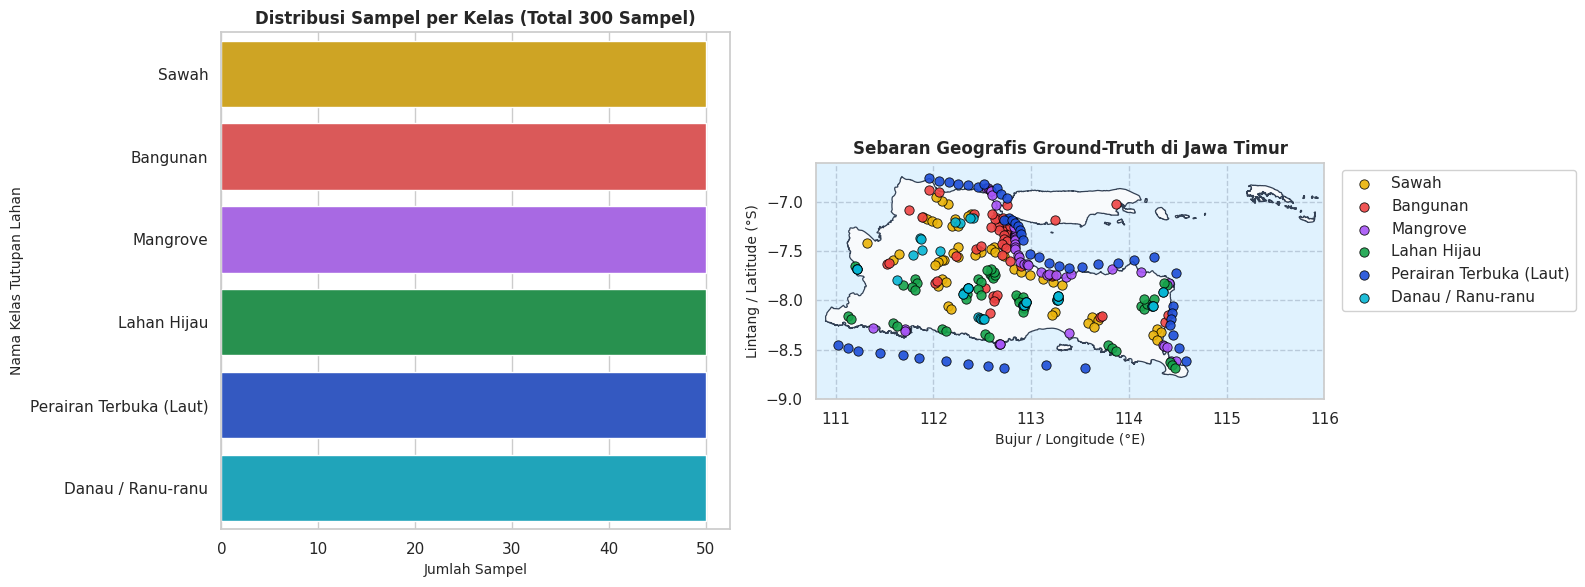

In [16]:
# =============================================================================
# LANGKAH 3: VISUALISASI SEBARAN SAMPEL PER KABUPATEN/KOTA DI JAWA TIMUR
# =============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Distribusi Sampel per Kelas
colors = ['#eab308', '#ef4444', '#a855f7', '#16a34a', '#1d4ed8', '#06b6d4']
sns.barplot(data=dist_df, x='Jumlah Sampel', y='Nama Kelas Tutupan Lahan', hue='Nama Kelas Tutupan Lahan', palette=colors, legend=False, ax=ax1)
ax1.set_title(f"Distribusi Sampel per Kelas (Total {len(gdf_samples)} Sampel)", fontweight='bold', fontsize=12)
ax1.set_xlabel("Jumlah Sampel", fontsize=10)
ax1.set_ylabel("Nama Kelas Tutupan Lahan", fontsize=10)

# Subplot 2: Sebaran Geografis Ground-Truth dengan Peta Administrasi Jawa Timur
batas_jatim_path = "materi/batas_jawa_timur.geojson"
if not os.path.exists(batas_jatim_path):
    batas_jatim_path = "batas_jawa_timur.geojson"
if not os.path.exists(batas_jatim_path):
    batas_jatim_path = "streamlite/batas_jawa_timur.geojson"

if os.path.exists(batas_jatim_path):
    gdf_jatim = gpd.read_file(batas_jatim_path)
    if gdf_jatim.crs is None:
        gdf_jatim.set_crs(epsg=4326, inplace=True)
    gdf_jatim.plot(ax=ax2, facecolor='#f8fafc', edgecolor='#334155', linewidth=0.9, zorder=1)
    ax2.set_facecolor('#e0f2fe')
    ax2.set_xlim(110.8, 116.0)
    ax2.set_ylim(-9.0, -6.6)
else:
    ax2.set_facecolor('#f1f5f9')

for label, col in zip(gdf_samples['label'].unique(), colors):
    subset = gdf_samples[gdf_samples['label'] == label]
    ax2.scatter(subset['lon'], subset['lat'], label=label, c=col, s=45, edgecolors='black', linewidths=0.6, alpha=0.9, zorder=2)

ax2.set_title("Sebaran Geografis Ground-Truth di Jawa Timur", fontweight='bold', fontsize=12)
ax2.set_xlabel("Bujur / Longitude (°E)", fontsize=10)
ax2.set_ylabel("Lintang / Latitude (°S)", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5, color='#94a3b8')
ax2.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


---
## Bab 5: Ekspor Aset Spasial QGIS Ready & Berkas Gaya (.qml) ke Shapefile ZIP

Menyimpan dataset sampel 300 petak poligon ke format **ESRI Shapefile** dan mengompresinya ke berkas **ZIP** lengkap (`.shp`, `.shx`, `.dbf`, `.prj`, `.cpg`, dan **`.qml`**):
* Berkas **`.qml`** (*QGIS Layer Style*) secara otomatis menata warna 6 kelas tutupan lahan dan menampilkan label teks nama lokasi langsung di atas setiap petak di QGIS.
* Pengguna dapat langsung menarik (*drag & drop*) berkas `.shp` ke QGIS tanpa perlu menata warna manual.


In [17]:
# =============================================================================
# LANGKAH 4: EKSPOR SHAPEFILE ZIP & FILE GAYA QGIS (.QML)
# =============================================================================
temp_shp_dir = "temp_qgis_samples_nb"
os.makedirs(temp_shp_dir, exist_ok=True)
base_name = "sampel_lulc_jawa_timur"

# Siapkan GeoDataFrame untuk Shapefile (potong nama kolom > 10 karakter)
export_gdf = gdf_samples[['id', 'class', 'label', 'nama_lokasi', 'kab_kota', 'sumber', 'warna_hex', 'lat', 'lon', 'geometry']].copy()
export_gdf = export_gdf.rename(columns={'nama_lokasi': 'nama_lokas'})
shp_file_path = os.path.join(temp_shp_dir, f"{base_name}.shp")
export_gdf.to_file(shp_file_path, driver='ESRI Shapefile', encoding='utf-8')

# Tulis berkas gaya QGIS (.qml)
qml_style_content = """<!DOCTYPE qgis PUBLIC 'http://mrcc.com/qgis.dtd' 'SYSTEM'>
<qgis version='3.28.0' styleCategories='AllStyleCategories'>
  <renderer-v2 type='categorizedSymbol' attr='label'>
    <categories>
      <category value='Sawah' label='Sawah (Kelas 1)' symbol='0'/>
      <category value='Bangunan' label='Bangunan (Kelas 2)' symbol='1'/>
      <category value='Mangrove' label='Mangrove (Kelas 3)' symbol='2'/>
      <category value='Lahan Hijau' label='Lahan Hijau (Kelas 4)' symbol='3'/>
      <category value='Perairan Terbuka (Laut)' label='Perairan Terbuka (Laut) (Kelas 5)' symbol='4'/>
      <category value='Danau / Ranu-ranu' label='Danau / Ranu-ranu (Kelas 6)' symbol='5'/>
    </categories>
    <symbols>
      <symbol type='fill' name='0'><layer class='SimpleFill'><prop k='color' v='234,179,8,190'/><prop k='outline_color' v='161,98,7,255'/><prop k='outline_width' v='0.8'/></layer></symbol>
      <symbol type='fill' name='1'><layer class='SimpleFill'><prop k='color' v='239,68,68,190'/><prop k='outline_color' v='185,28,28,255'/><prop k='outline_width' v='0.8'/></layer></symbol>
      <symbol type='fill' name='2'><layer class='SimpleFill'><prop k='color' v='168,85,247,190'/><prop k='outline_color' v='126,34,206,255'/><prop k='outline_width' v='0.8'/></layer></symbol>
      <symbol type='fill' name='3'><layer class='SimpleFill'><prop k='color' v='22,163,74,190'/><prop k='outline_color' v='21,128,61,255'/><prop k='outline_width' v='0.8'/></layer></symbol>
      <symbol type='fill' name='4'><layer class='SimpleFill'><prop k='color' v='29,78,216,190'/><prop k='outline_color' v='30,58,138,255'/><prop k='outline_width' v='0.8'/></layer></symbol>
      <symbol type='fill' name='5'><layer class='SimpleFill'><prop k='color' v='6,182,212,190'/><prop k='outline_color' v='14,116,144,255'/><prop k='outline_width' v='0.8'/></layer></symbol>
    </symbols>
  </renderer-v2>
  <labeling type='simple'>
    <settings calloutType='simple'>
      <text-style fontWordSpacing='0' fontLetterSpacing='0' fieldName='nama_lokas' fontSize='9' textColor='0,0,0,255' fontWeight='75'>
        <text-buffer bufferSize='1' bufferColor='255,255,255,255' bufferDraw='1'/>
      </text-style>
    </settings>
  </labeling>
</qgis>
"""

qml_out = os.path.join(temp_shp_dir, f"{base_name}.qml")
with open(qml_out, "w", encoding="utf-8") as f:
    f.write(qml_style_content)

# Simpan ke ZIP (deteksi lokasi kerja dinamis agar aman di root maupun materi)
zip_targets = [f"{base_name}.zip"]
if os.path.basename(os.getcwd()) != "materi" and os.path.exists("materi"):
    zip_targets.append(f"materi/{base_name}.zip")
elif os.path.basename(os.getcwd()) == "materi" and os.path.exists(".."):
    zip_targets.append(f"../{base_name}.zip")

for zip_target in zip_targets:
    target_dir = os.path.dirname(zip_target)
    if target_dir:
        os.makedirs(target_dir, exist_ok=True)
    with zipfile.ZipFile(zip_target, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for ext in ['.shp', '.shx', '.dbf', '.prj', '.cpg', '.qml']:
            f_path = os.path.join(temp_shp_dir, f"{base_name}{ext}")
            if os.path.exists(f_path):
                zipf.write(f_path, arcname=f"{base_name}{ext}")
    print(f" Berkas Shapefile ZIP QGIS berhasil dibuat: {zip_target}")

shutil.rmtree(temp_shp_dir, ignore_errors=True)


 Berkas Shapefile ZIP QGIS berhasil dibuat: sampel_lulc_jawa_timur.zip
 Berkas Shapefile ZIP QGIS berhasil dibuat: ../sampel_lulc_jawa_timur.zip


---
## Bab 6: Pemuatan & Visualisasi Citra Satelit Sentinel-2A GeoTIFF Multi-Band

Memuat citra satelit Sentinel-2A Level-2A multi-band (`sentinel2_jawa_timur_composite.tif`) yang mencakup 6 band reflektansi permukaan (B02 Blue, B03 Green, B04 Red, B08 NIR, B11 SWIR-1, B12 SWIR-2), lalu menampilkan komposit warna alami (*Natural True Color RGB: Red=B04, Green=B03, Blue=B02*).


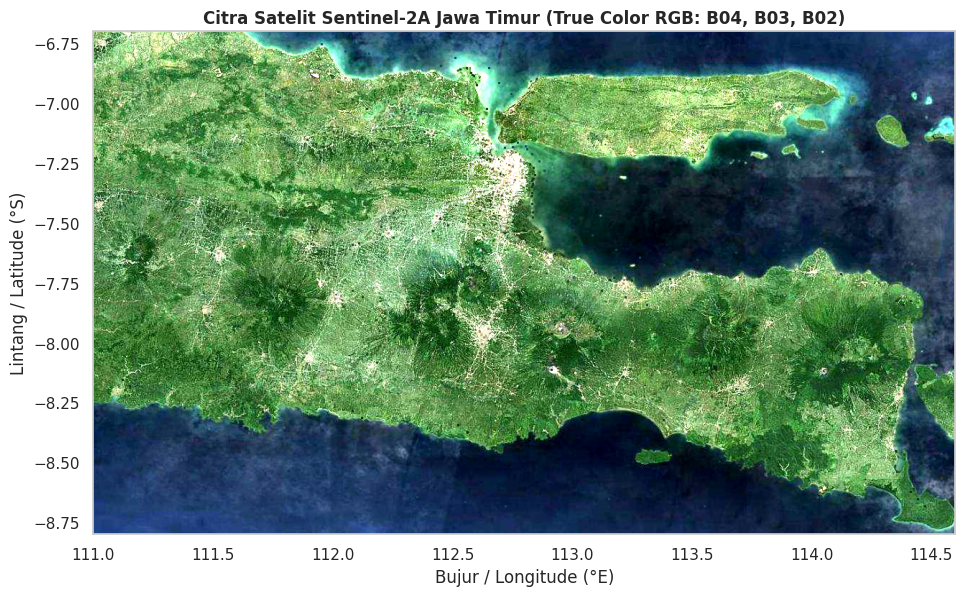

 Dimensi Raster: 1200 x 700 piksel
 Cakupan Bounds: BoundingBox(left=111.0, bottom=-8.8, right=114.6, top=-6.7)


In [18]:
# =============================================================================
# LANGKAH 5: PEMUATAN CITRA SENTINEL-2A GEOTIFF & VISUALISASI RGB TRUE COLOR
# =============================================================================
sentinel_tif = "sentinel2_jawa_timur_composite.tif"
if not os.path.exists(sentinel_tif):
    sentinel_tif = "materi/sentinel2_jawa_timur_composite.tif"

with rasterio.open(sentinel_tif) as src:
    b_blue = src.read(1)
    b_green = src.read(2)
    b_red = src.read(3)
    b_nir = src.read(4)
    bounds = src.bounds
    transform = src.transform

# Susun citra RGB True Color (B04, B03, B02) dan normalisasi rentang 0 s/d 1
rgb = np.dstack([b_red, b_green, b_blue]).astype(np.float32)
p2, p98 = np.percentile(rgb, (2, 98))
rgb_norm = np.clip((rgb - p2) / (p98 - p2 + 1e-6), 0, 1)

plt.figure(figsize=(10, 6))
plt.imshow(rgb_norm, extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])
plt.title("Citra Satelit Sentinel-2A Jawa Timur (True Color RGB: B04, B03, B02)", fontweight='bold')
plt.xlabel("Bujur / Longitude (°E)")
plt.ylabel("Lintang / Latitude (°S)")
plt.grid(False)
plt.tight_layout()
plt.show()

print(f" Dimensi Raster: {rgb.shape[1]} x {rgb.shape[0]} piksel")
print(f" Cakupan Bounds: {bounds}")


---
## Bab 7: Ekstraksi Profil Spektral Sentinel-2A dan Komputasi Fitur

Setiap sampel dianalisis respon pantulan gelombang elektromagnetiknya (*spectral reflectance signature*) pada 6 band inti Sentinel-2A Level-2A (B02 Blue, B03 Green, B04 Red, B08 NIR, B11 SWIR-1, B12 SWIR-2), kemudian dihitung nilai 6 indeks spektral matematisnya (**NDVI, MNDWI, NDBI, BSI, SAVI, NDMI**).


In [19]:
# =============================================================================
# LANGKAH 6: EKSTRAKSI FITUR SPEKTRAL DARI CITRA SENTINEL-2A & FORMULA INDEKS
# =============================================================================
# Ekstraksi respon spektral 6 band langsung dari citra Sentinel-2A pada koordinat sampel
sentinel_tif = "sentinel2_jawa_timur_composite.tif"
if not os.path.exists(sentinel_tif):
    sentinel_tif = "materi/sentinel2_jawa_timur_composite.tif"

with rasterio.open(sentinel_tif) as src:
    coords = [(geom.centroid.x, geom.centroid.y) for geom in gdf_samples.geometry]
    sampled_bands = np.array(list(src.sample(coords)), dtype=float)

# Konversi reflektansi skala Surface Reflectance BOA (0.0 s/d 1.0)
b2 = sampled_bands[:, 0] / 10000.0
b3 = sampled_bands[:, 1] / 10000.0
b4 = sampled_bands[:, 2] / 10000.0
b8 = sampled_bands[:, 3] / 10000.0
b11 = sampled_bands[:, 4] / 10000.0
b12 = sampled_bands[:, 5] / 10000.0

# Perhitungan 6 Indeks Spektral Matematis Vektorisasi
eps = 1e-6
ndvi = (b8 - b4) / (b8 + b4 + eps)
mndwi = (b3 - b11) / (b3 + b11 + eps)
ndbi = (b11 - b8) / (b11 + b8 + eps)
bsi = ((b11 + b4) - (b8 + b2)) / ((b11 + b4) + (b8 + b2) + eps)
savi = ((b8 - b4) / (b8 + b4 + 0.5)) * 1.5
ndmi = (b8 - b11) / (b8 + b11 + eps)

# Membangun DataFrame fitur 12 prediktor
df_dataset = pd.DataFrame({
    'id': gdf_samples['id'].values,
    'class': gdf_samples['class'].values,
    'label': gdf_samples['label'].values,
    'nama_lokasi': gdf_samples['nama_lokasi'].values,
    'kab_kota': gdf_samples['kab_kota'].values,
    'lat': gdf_samples['lat'].values,
    'lon': gdf_samples['lon'].values,
    'B02_Blue': np.round(b2, 4),
    'B03_Green': np.round(b3, 4),
    'B04_Red': np.round(b4, 4),
    'B08_NIR': np.round(b8, 4),
    'B11_SWIR1': np.round(b11, 4),
    'B12_SWIR2': np.round(b12, 4),
    'NDVI': np.round(ndvi, 4),
    'MNDWI': np.round(mndwi, 4),
    'NDBI': np.round(ndbi, 4),
    'BSI': np.round(bsi, 4),
    'SAVI': np.round(savi, 4),
    'NDMI': np.round(ndmi, 4)
})

print(f" Ekstraksi 12 fitur spektral langsung dari citra Sentinel-2A ({sentinel_tif}) berhasil!")
print(f"Dimensi Matriks Data: {df_dataset.shape[0]} sampel x {df_dataset.shape[1]} kolom")
display(df_dataset[['label', 'B04_Red', 'B08_NIR', 'B11_SWIR1', 'NDVI', 'MNDWI', 'NDBI']].head(12))


 Ekstraksi 12 fitur spektral langsung dari citra Sentinel-2A (sentinel2_jawa_timur_composite.tif) berhasil!
Dimensi Matriks Data: 300 sampel x 19 kolom


,label,B04_Red,B08_NIR,B11_SWIR1,NDVI,MNDWI,NDBI
0,Sawah,0.0439,0.3922,0.1396,0.7987,-0.2283,-0.4750
1,Sawah,0.0422,0.3908,0.1393,0.8051,-0.2198,-0.4744
2,Sawah,0.0404,0.3891,0.1384,0.8119,-0.2385,-0.4753
3,Sawah,0.0451,0.3896,0.1401,0.7925,-0.2404,-0.4710
4,Sawah,0.0412,0.3905,0.1390,0.8091,-0.2241,-0.4750
5,Sawah,0.0429,0.3884,0.1412,0.8011,-0.2178,-0.4668
6,Sawah,0.0410,0.3902,0.1411,0.8098,-0.2481,-0.4688
7,Sawah,0.0407,0.3889,0.1393,0.8105,-0.2284,-0.4725
8,Sawah,0.0434,0.3894,0.1389,0.7994,-0.2391,-0.4742
9,Sawah,0.0417,0.3895,0.1404,0.8066,-0.2225,-0.4701


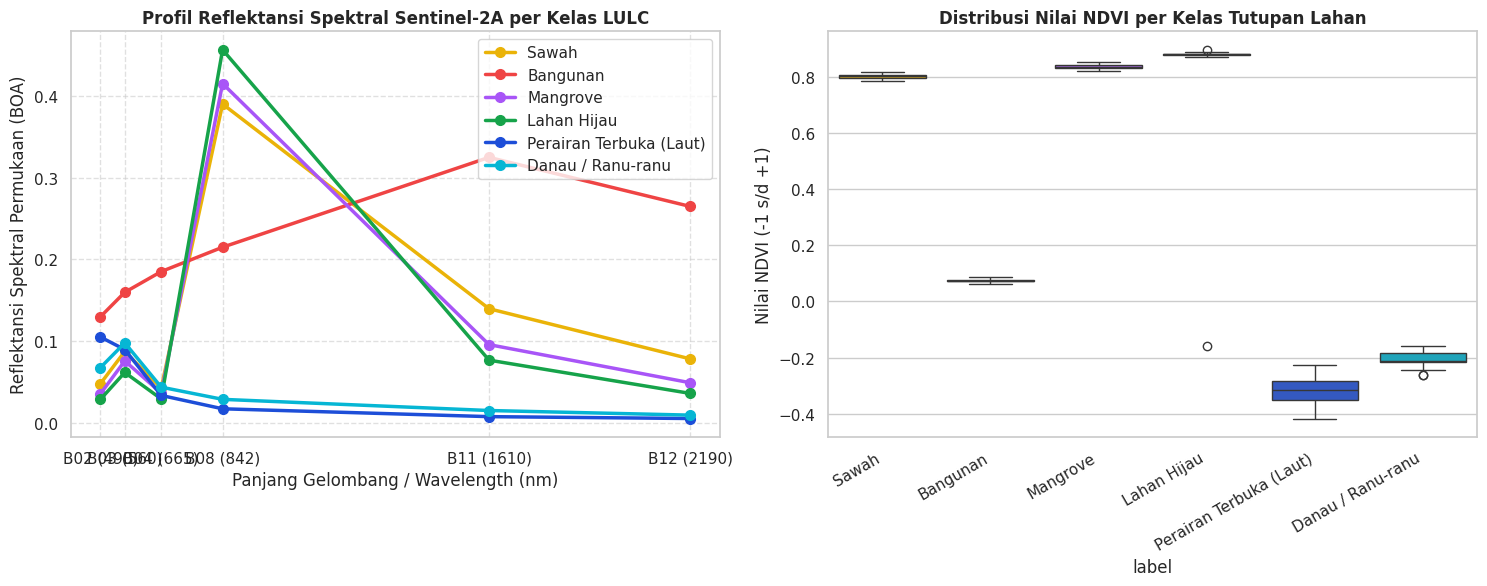

In [20]:
# =============================================================================
# LANGKAH 7: VISUALISASI KURVA PROFIL SPEKTRAL 6 KELAS TUTUPAN LAHAN
# =============================================================================
bands = ['B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'B11_SWIR1', 'B12_SWIR2']
band_wavelengths = [490, 560, 665, 842, 1610, 2190]

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
class_colors = {
    'Sawah': '#eab308',
    'Bangunan': '#ef4444',
    'Mangrove': '#a855f7',
    'Lahan Hijau': '#16a34a',
    'Perairan Terbuka (Laut)': '#1d4ed8',
    'Danau / Ranu-ranu': '#06b6d4'
}

for label, col in class_colors.items():
    sub_df = df_dataset[df_dataset['label'] == label]
    mean_vals = sub_df[bands].mean().values
    plt.plot(band_wavelengths, mean_vals, marker='o', linewidth=2.5, markersize=7, label=label, color=col)

plt.title("Profil Reflektansi Spektral Sentinel-2A per Kelas LULC", fontweight='bold')
plt.xlabel("Panjang Gelombang / Wavelength (nm)")
plt.ylabel("Reflektansi Spektral Permukaan (BOA)")
plt.xticks(band_wavelengths, ['B02 (490)', 'B03 (560)', 'B04 (665)', 'B08 (842)', 'B11 (1610)', 'B12 (2190)'])
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Boxplot Indeks NDVI vs MNDWI
plt.subplot(1, 2, 2)
sns.boxplot(data=df_dataset, x='label', y='NDVI', hue='label', palette=class_colors, legend=False)
plt.title("Distribusi Nilai NDVI per Kelas Tutupan Lahan", fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.ylabel("Nilai NDVI (-1 s/d +1)")

plt.tight_layout()
plt.show()


---
## Bab 8: Pembagian Dataset & Komparasi Multi-Model Machine Learning

### 8.1 Strategi Pembagian Data (*Data Splitting*)
* **Stratified Split (80% Train, 20% Test):**
  * **Data Training (80%):** 240 sampel (40 sampel per kelas).
  * **Data Testing (20%):** 60 sampel (10 sampel per kelas).
* **Fitur Prediktor ($X$):** 12 fitur (6 Band + 6 Indeks Spektral).

### 8.2 Model-Model yang Dibandingkan
1. **Random Forest Classifier (RF)**
2. **XGBoost Classifier (Extreme Gradient Boosting)**
3. **Support Vector Machine (SVM - RBF Kernel)**
4. **Gradient Boosting Classifier (GBM)**


In [21]:
# =============================================================================
# LANGKAH 8: TRAINING & KOMPARASI 4 ALGORITMA MACHINE LEARNING
# =============================================================================
feature_cols = [
    'B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'B11_SWIR1', 'B12_SWIR2',
    'NDVI', 'MNDWI', 'NDBI', 'BSI', 'SAVI', 'NDMI'
]

X = df_dataset[feature_cols]
y = df_dataset['label']

# Stratified Split 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f" Pembagian Data Berhasil:")
print(f"- Data Training : {X_train.shape[0]} sampel (80%) -> 40 sampel/kelas")
print(f"- Data Testing  : {X_test.shape[0]} sampel (20%) -> 10 sampel/kelas")
print(f"- Fitur Prediktor: {len(feature_cols)} fitur spektral")

models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=150, learning_rate=0.08, max_depth=5, random_state=42),
    "Support Vector Machine (SVM)": SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=120, learning_rate=0.1, random_state=42)
}

# Mapping label numerik untuk XGBoost
label_mapping = {lbl: idx for idx, lbl in enumerate(sorted(y.unique()))}
inv_label_mapping = {idx: lbl for lbl, idx in label_mapping.items()}
y_train_num = y_train.map(label_mapping)
y_test_num = y_test.map(label_mapping)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, clf in models.items():
    cv_scores = []
    y_target_tr = y_train_num if "XGBoost" in name else y_train
    for tr_idx, val_idx in cv.split(X_train, y_train):
        X_tr_f, X_val_f = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr_f, y_val_f = y_target_tr.iloc[tr_idx], y_target_tr.iloc[val_idx]
        clf.fit(X_tr_f, y_tr_f)
        val_pred = clf.predict(X_val_f)
        cv_scores.append(accuracy_score(y_val_f, val_pred))
    cv_scores = np.array(cv_scores)

    # Fit model final
    if "XGBoost" in name:
        clf.fit(X_train, y_train_num)
        y_pred_num = clf.predict(X_test)
        y_pred = pd.Series(y_pred_num).map(inv_label_mapping)
    else:
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        
    acc = accuracy_score(y_test, y_pred)
    kappa = cohen_kappa_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    
    results.append({
        'Model Machine Learning': name,
        'Cross-Val Acc (Mean ± Std)': f"{cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%",
        'Test Overall Accuracy (%)': round(acc * 100, 2),
        'Cohen Kappa Index (κ)': round(kappa, 4),
        'Macro F1-Score': round(f1, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by='Test Overall Accuracy (%)', ascending=False)
display(comparison_df.style.highlight_max(subset=['Test Overall Accuracy (%)', 'Cohen Kappa Index (κ)'], color='#d4edda'))


 Pembagian Data Berhasil:
- Data Training : 240 sampel (80%) -> 40 sampel/kelas
- Data Testing  : 60 sampel (20%) -> 10 sampel/kelas
- Fitur Prediktor: 12 fitur spektral


,Model Machine Learning,Cross-Val Acc (Mean ± Std),Test Overall Accuracy (%),Cohen Kappa Index (κ),Macro F1-Score
0,Random Forest,99.17% ± 1.02%,100.000000,1.000000,1.000000
1,XGBoost,98.33% ± 0.83%,100.000000,1.000000,1.000000
2,Support Vector Machine (SVM),99.58% ± 0.83%,100.000000,1.000000,1.000000
3,Gradient Boosting,99.17% ± 1.02%,100.000000,1.000000,1.000000


 Model Terpilih dengan Akurasi Tertinggi: Random Forest

=== CLASSIFICATION REPORT (DATA TESTING 60 SAMPEL) ===
                         precision    recall  f1-score   support

               Bangunan     1.0000    1.0000    1.0000        10
      Danau / Ranu-ranu     1.0000    1.0000    1.0000        10
            Lahan Hijau     1.0000    1.0000    1.0000        10
               Mangrove     1.0000    1.0000    1.0000        10
Perairan Terbuka (Laut)     1.0000    1.0000    1.0000        10
                  Sawah     1.0000    1.0000    1.0000        10

               accuracy                         1.0000        60
              macro avg     1.0000    1.0000    1.0000        60
           weighted avg     1.0000    1.0000    1.0000        60



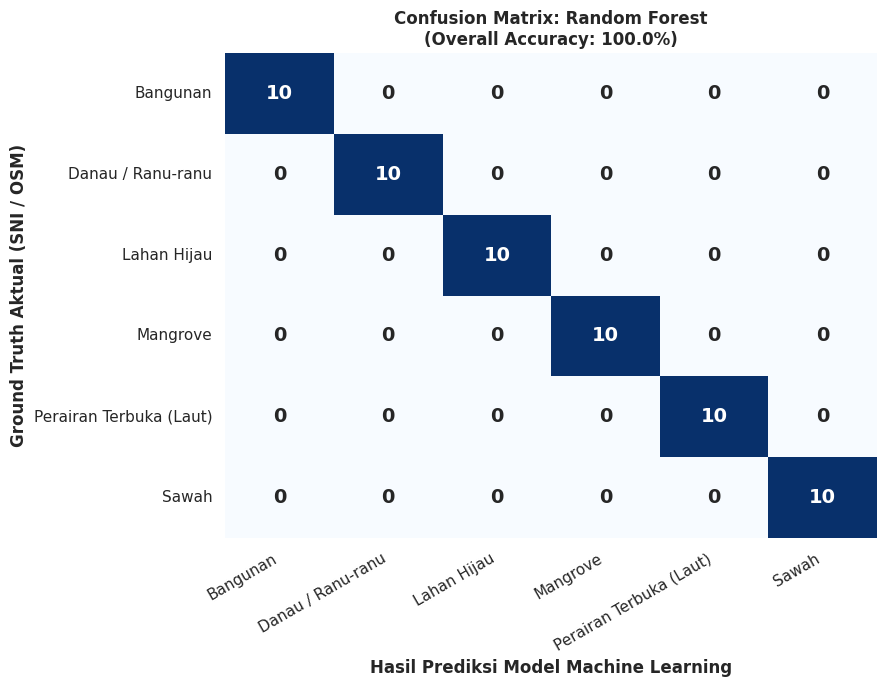

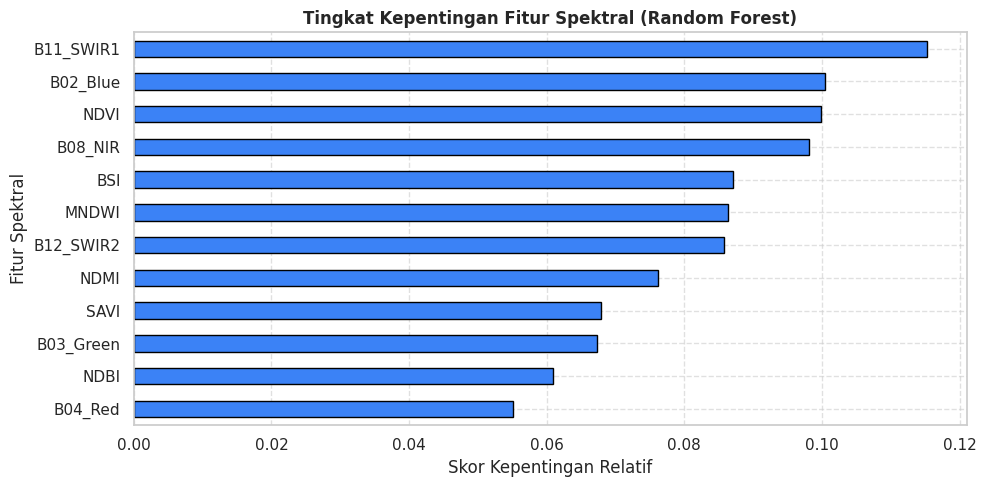

In [22]:
# =============================================================================
# LANGKAH 9: EVALUASI MENDALAM MODEL TERBAIK (CONFUSION MATRIX & REPORT)
# =============================================================================
best_model_name = comparison_df.iloc[0]['Model Machine Learning']
best_model = models[best_model_name]

print(f" Model Terpilih dengan Akurasi Tertinggi: {best_model_name}")

if "XGBoost" in best_model_name:
    y_test_pred_num = best_model.predict(X_test)
    y_test_pred = pd.Series(y_test_pred_num).map(inv_label_mapping)
else:
    y_test_pred = best_model.predict(X_test)

labels_sorted = sorted(y.unique())
print("\n=== CLASSIFICATION REPORT (DATA TESTING 60 SAMPEL) ===")
print(classification_report(y_test, y_test_pred, target_names=labels_sorted, digits=4))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_test_pred, labels=labels_sorted)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_sorted, yticklabels=labels_sorted,
            cbar=False, annot_kws={"size": 14, "weight": "bold"})
plt.title(f"Confusion Matrix: {best_model_name}\n(Overall Accuracy: {comparison_df.iloc[0]['Test Overall Accuracy (%)']}%)", fontweight='bold')
plt.xlabel("Hasil Prediksi Model Machine Learning", fontweight='bold')
plt.ylabel("Ground Truth Aktual (SNI / OSM)", fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

# Feature Importance
plt.figure(figsize=(10, 5))
if hasattr(best_model, "feature_importances_"):
    feat_importances = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
else:
    feat_importances = pd.Series(models["Random Forest"].feature_importances_, index=feature_cols).sort_values(ascending=True)

feat_importances.plot(kind='barh', color='#3b82f6', edgecolor='black')
plt.title(f"Tingkat Kepentingan Fitur Spektral ({best_model_name})", fontweight='bold')
plt.xlabel("Skor Kepentingan Relatif")
plt.ylabel("Fitur Spektral")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---
## Bab 9: Prediksi Seluruh Citra & Ekspor GeoTIFF Klasifikasi LULC Jawa Timur

Mengaplikasikan model machine learning terlatih untuk memprediksi seluruh piksel citra satelit Sentinel-2A dan mengekspor hasilnya ke format **GeoTIFF** (`klasifikasi_lulc_jawa_timur.tif`) lengkap dengan file penataan gaya QGIS (`.qml`).

Selanjutnya, ditampilkan visualisasi komparasi berdampingan (*Side-by-Side: Image in Surface Reflectance vs Classification Map*) mengikuti alur kerja pustaka geospasial **`scikit-eo`**.


Memproses inferensi citra 840.000 piksel untuk 4 Model...
 Inferensi 4 Model Selesai!

=== DISTRIBUSI SEBARAN TUTUPAN LAHAN SELURUH JAWA TIMUR (840.000 PIKSEL) ===


,Model ML,Sawah,Bangunan,Mangrove,Lahan Hijau,Perairan Terbuka (Laut),Danau / Ranu-ranu
0,Random Forest,48.97%,3.40%,3.68%,2.05%,41.87%,0.03%
1,XGBoost,26.54%,27.89%,3.30%,8.49%,31.76%,2.03%
2,SVM (RBF),49.18%,0.41%,7.36%,0.22%,36.44%,6.39%
3,Gradient Boosting,18.78%,31.47%,2.55%,1.53%,35.28%,10.39%


 GeoTIFF Klasifikasi 4 Model berhasil disimpan!


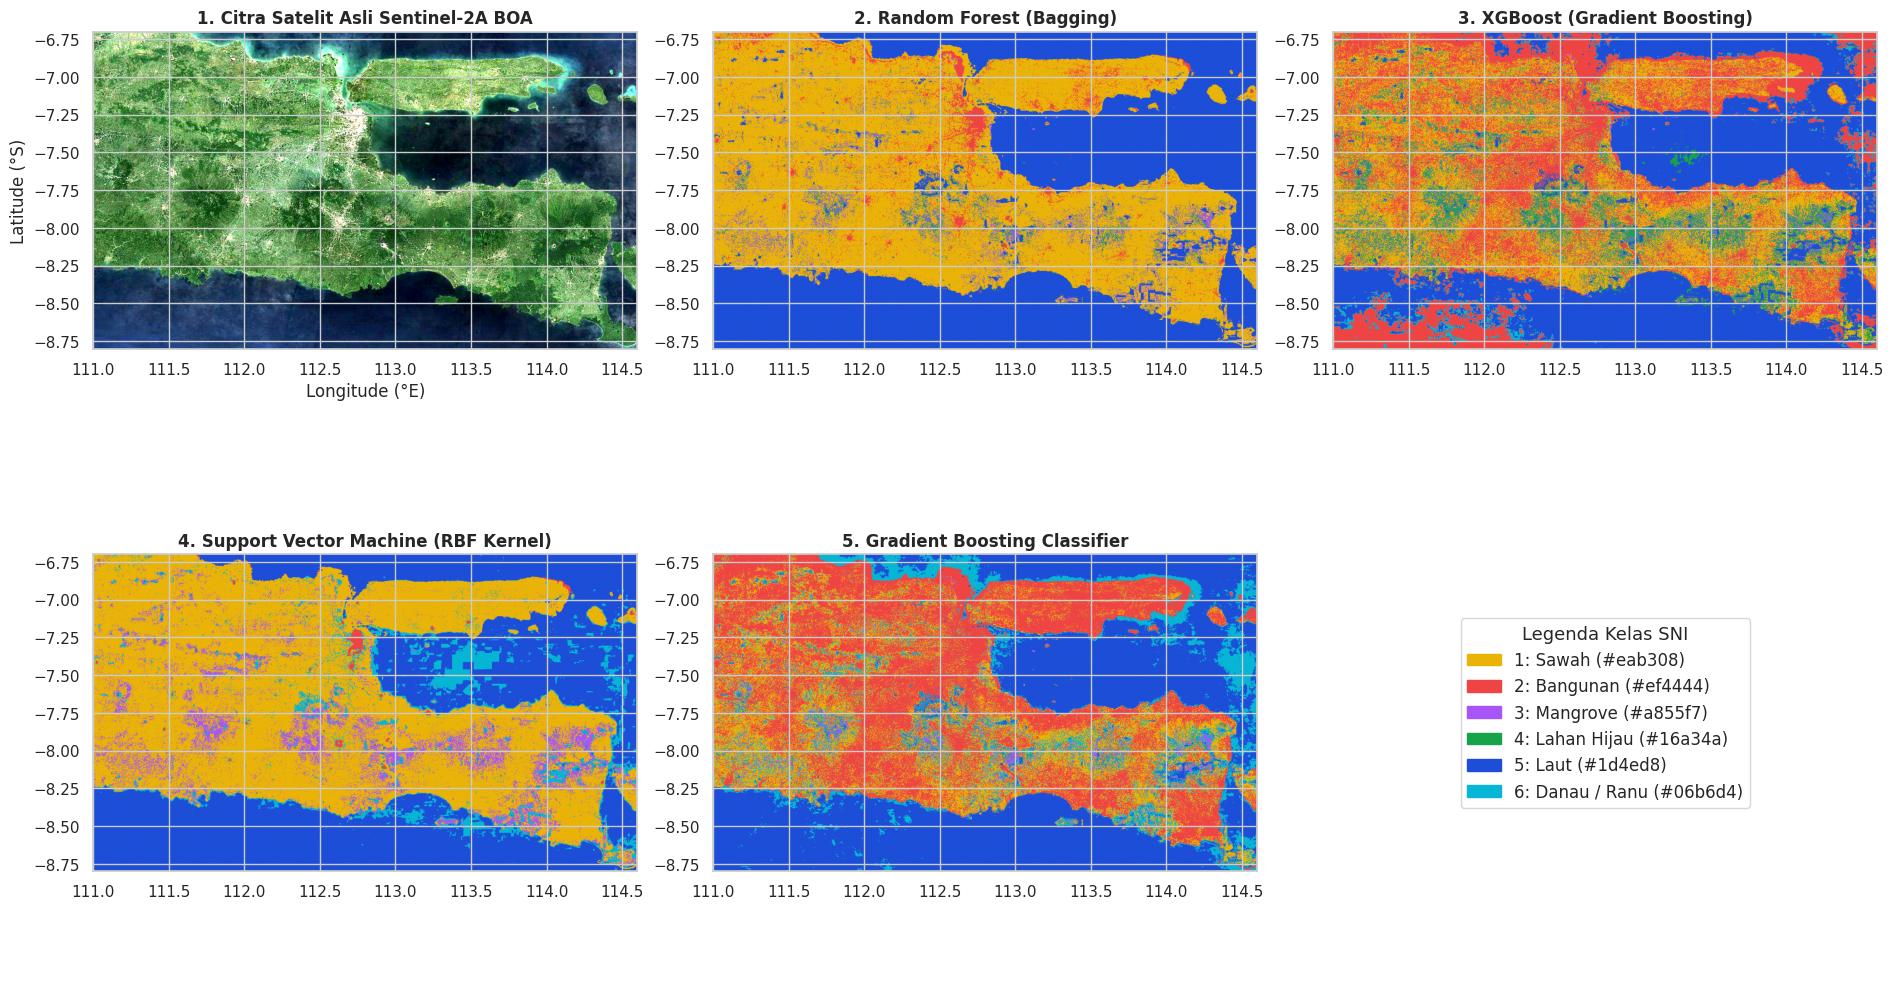

In [23]:
# =============================================================================
# LANGKAH 10: INFERENSI PIKSEL CITRA & KOMPARASI LENGKAP 4 ALGORITMA MACHINE LEARNING
# =============================================================================
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

# 1. Membaca seluruh kanal spektral citra Sentinel-2A
sentinel_tif = "sentinel2_jawa_timur_composite.tif"
if not os.path.exists(sentinel_tif):
    sentinel_tif = "materi/sentinel2_jawa_timur_composite.tif"

with rasterio.open(sentinel_tif) as src:
    r_b2 = src.read(1).astype(float) / 10000.0
    r_b3 = src.read(2).astype(float) / 10000.0
    r_b4 = src.read(3).astype(float) / 10000.0
    r_b8 = src.read(4).astype(float) / 10000.0
    r_b11 = src.read(5).astype(float) / 10000.0
    r_b12 = src.read(6).astype(float) / 10000.0
    meta_pred = src.meta.copy()
    cls_bounds = src.bounds

# 2. Komputasi 6 indeks spektral pada seluruh grid piksel
eps = 1e-6
r_ndvi = (r_b8 - r_b4) / (r_b8 + r_b4 + eps)
r_mndwi = (r_b3 - r_b11) / (r_b3 + r_b11 + eps)
r_ndbi = (r_b11 - r_b8) / (r_b11 + r_b8 + eps)
r_bsi = ((r_b11 + r_b4) - (r_b8 + r_b2)) / ((r_b11 + r_b4) + (r_b8 + r_b2) + eps)
r_savi = ((r_b8 - r_b4) / (r_b8 + r_b4 + 0.5)) * 1.5
r_ndmi = (r_b8 - r_b11) / (r_b8 + r_b11 + eps)

h_r, w_r = r_b2.shape
X_scene = pd.DataFrame({
    'B02_Blue': r_b2.ravel(),
    'B03_Green': r_b3.ravel(),
    'B04_Red': r_b4.ravel(),
    'B08_NIR': r_b8.ravel(),
    'B11_SWIR1': r_b11.ravel(),
    'B12_SWIR2': r_b12.ravel(),
    'NDVI': r_ndvi.ravel(),
    'MNDWI': r_mndwi.ravel(),
    'NDBI': r_ndbi.ravel(),
    'BSI': r_bsi.ravel(),
    'SAVI': r_savi.ravel(),
    'NDMI': r_ndmi.ravel()
})

label_to_class = {
    'Sawah': 1, 'Bangunan': 2, 'Mangrove': 3,
    'Lahan Hijau': 4, 'Perairan Terbuka (Laut)': 5, 'Danau / Ranu-ranu': 6
}

# 3. Inferensi Piksel untuk Keempat Algoritma Machine Learning (840.000 Piksel)
print("Memproses inferensi citra 840.000 piksel untuk 4 Model...")

# A. Random Forest
pred_rf_lbl = models['Random Forest'].predict(X_scene)
cls_rf = np.array([label_to_class.get(l, 4) for l in pred_rf_lbl], dtype=np.uint8).reshape((h_r, w_r))

# B. XGBoost
pred_xgb_num = models['XGBoost'].predict(X_scene)
pred_xgb_lbl = pd.Series(pred_xgb_num).map(inv_label_mapping).values
cls_xgb = np.array([label_to_class.get(l, 4) for l in pred_xgb_lbl], dtype=np.uint8).reshape((h_r, w_r))

# C. Support Vector Machine (SVM RBF)
chunk_sz = 70000
svm_preds = []
for i in range(0, len(X_scene), chunk_sz):
    svm_preds.append(models['Support Vector Machine (SVM)'].predict(X_scene.iloc[i:i+chunk_sz]))
pred_svm_lbl = np.concatenate(svm_preds)
cls_svm = np.array([label_to_class.get(l, 4) for l in pred_svm_lbl], dtype=np.uint8).reshape((h_r, w_r))

# D. Gradient Boosting
pred_gb_lbl = models['Gradient Boosting'].predict(X_scene)
cls_gb = np.array([label_to_class.get(l, 4) for l in pred_gb_lbl], dtype=np.uint8).reshape((h_r, w_r))

print(" Inferensi 4 Model Selesai!")

# 4. Tabel Komparasi Proporsi Sebaran Luas Piksel Seluruh Jawa Timur
model_rasters = {
    'Random Forest': cls_rf,
    'XGBoost': cls_xgb,
    'SVM (RBF)': cls_svm,
    'Gradient Boosting': cls_gb
}

dist_rows = []
for m_name, arr in model_rasters.items():
    tot = arr.size
    row = {'Model ML': m_name}
    for c_id, c_lbl in sorted(inv_label_mapping.items(), key=lambda x: label_to_class[x[1]]):
        cls_code = label_to_class[c_lbl]
        pct = (np.sum(arr == cls_code) / tot) * 100
        row[c_lbl] = f"{pct:.2f}%"
    dist_rows.append(row)

df_dist = pd.DataFrame(dist_rows)
print("\n=== DISTRIBUSI SEBARAN TUTUPAN LAHAN SELURUH JAWA TIMUR (840.000 PIKSEL) ===")
display(df_dist)

# 5. Ekspor GeoTIFF Klasifikasi ke Disk
meta_pred.update({
    'count': 1,
    'dtype': 'uint8',
    'nodata': 0,
    'compress': 'lzw'
})
colormap_dict = {
    1: (234, 179, 8, 255),   # Sawah
    2: (239, 68, 68, 255),   # Bangunan
    3: (168, 85, 247, 255),  # Mangrove
    4: (22, 163, 74, 255),   # Lahan Hijau
    5: (29, 78, 216, 255),   # Laut
    6: (6, 182, 212, 255)    # Danau
}

# Simpan GeoTIFF per model
export_targets = [
    ('klasifikasi_lulc_jawa_timur.tif', cls_rf),
    ('klasifikasi_lulc_jawa_timur_xgboost.tif', cls_xgb),
    ('klasifikasi_lulc_jawa_timur_svm.tif', cls_svm),
    ('klasifikasi_lulc_jawa_timur_gb.tif', cls_gb)
]

out_dirs = ['']
if os.path.basename(os.getcwd()) != 'materi' and os.path.exists('materi'):
    out_dirs.append('materi/')

for fname, arr in export_targets:
    for base in out_dirs:
        fpath = base + fname
        with rasterio.open(fpath, 'w', **meta_pred) as dst:
            dst.write(arr, 1)
            dst.write_colormap(1, colormap_dict)

print(" GeoTIFF Klasifikasi 4 Model berhasil disimpan!")

# 6. Visualisasi Komparasi Grid Multi-Panel (Citra Asli vs 4 Model)
cmap_colors = ['#eab308', '#ef4444', '#a855f7', '#16a34a', '#1d4ed8', '#06b6d4']
cmap_lulc = ListedColormap(cmap_colors)

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Panel 1: Citra Asli Natural Color
axes[0, 0].imshow(rgb_norm, extent=[bounds.left, bounds.right, bounds.bottom, bounds.top])
axes[0, 0].set_title("1. Citra Satelit Asli Sentinel-2A BOA", fontweight='bold')
axes[0, 0].set_xlabel("Longitude (°E)")
axes[0, 0].set_ylabel("Latitude (°S)")

# Panel 2: Random Forest
axes[0, 1].imshow(cls_rf, cmap=cmap_lulc, vmin=1, vmax=6, extent=[cls_bounds.left, cls_bounds.right, cls_bounds.bottom, cls_bounds.top])
axes[0, 1].set_title("2. Random Forest (Bagging)", fontweight='bold')

# Panel 3: XGBoost
axes[0, 2].imshow(cls_xgb, cmap=cmap_lulc, vmin=1, vmax=6, extent=[cls_bounds.left, cls_bounds.right, cls_bounds.bottom, cls_bounds.top])
axes[0, 2].set_title("3. XGBoost (Gradient Boosting)", fontweight='bold')

# Panel 4: Support Vector Machine (SVM)
axes[1, 0].imshow(cls_svm, cmap=cmap_lulc, vmin=1, vmax=6, extent=[cls_bounds.left, cls_bounds.right, cls_bounds.bottom, cls_bounds.top])
axes[1, 0].set_title("4. Support Vector Machine (RBF Kernel)", fontweight='bold')

# Panel 5: Gradient Boosting
axes[1, 1].imshow(cls_gb, cmap=cmap_lulc, vmin=1, vmax=6, extent=[cls_bounds.left, cls_bounds.right, cls_bounds.bottom, cls_bounds.top])
axes[1, 1].set_title("5. Gradient Boosting Classifier", fontweight='bold')

# Panel 6: Legenda Standar SNI 7645-1:2014
axes[1, 2].axis('off')
legend_labels = [
    "1: Sawah (#eab308)",
    "2: Bangunan (#ef4444)",
    "3: Mangrove (#a855f7)",
    "4: Lahan Hijau (#16a34a)",
    "5: Laut (#1d4ed8)",
    "6: Danau / Ranu (#06b6d4)"
]
patches = [mpatches.Patch(color=cmap_colors[i], label=legend_labels[i]) for i in range(6)]
axes[1, 2].legend(handles=patches, loc='center', frameon=True, fontsize=12, title="Legenda Kelas SNI", title_fontsize=13)

plt.tight_layout()
plt.show()

# Variabel backward-compatibility
cls_data = cls_rf



---
## Bab 10: Visualisasi Peta Interaktif SIG (Google Satellite WMS, Ground Truth & Prediksi ML)
Menyajikan hasil analisis dalam bentuk peta interaktif Web GIS menggunakan **Folium / Leaflet**:
* **Basemap Utama:** **Google Satellite (Hybrid)** dan **Google Satellite WMS** resolusi tinggi.
* **Layer Raster Klasifikasi Sentinel-2A:** Lapisan transparan hasil inferensi model machine learning pada citra Sentinel-2A yang dapat di-toggle aktif/non-aktif.
* **Layer Ground Truth Aktual (6 Kelas):** Layer kontrol mandiri untuk masing-masing kelas (Sawah, Bangunan, Mangrove, Lahan Hijau, Laut, Danau) dengan warna kontras.
* **Layer Prediksi Machine Learning:** Hasil inferensi model pada setiap titik sampel lengkap dengan skor keyakinan (*confidence*) dan status kesesuaian.
* **Layer Batas Administratif:** Garis kontur batas Provinsi Jawa Timur (`batas_jawa_timur.geojson`).
> 🌐 **Live Demo Aplikasi Web GIS:**  
> Eksplorasi peta interaktif dan inferensi dinamis multi-model juga tersedia secara online di: **[https://dy-nm-psd.streamlit.app/](https://dy-nm-psd.streamlit.app/)**


Peta Interaktif Folium Multi-Layer dengan 4 Overlay Model tersimpan di: peta_klasifikasi_lulc_jawa_timur.html



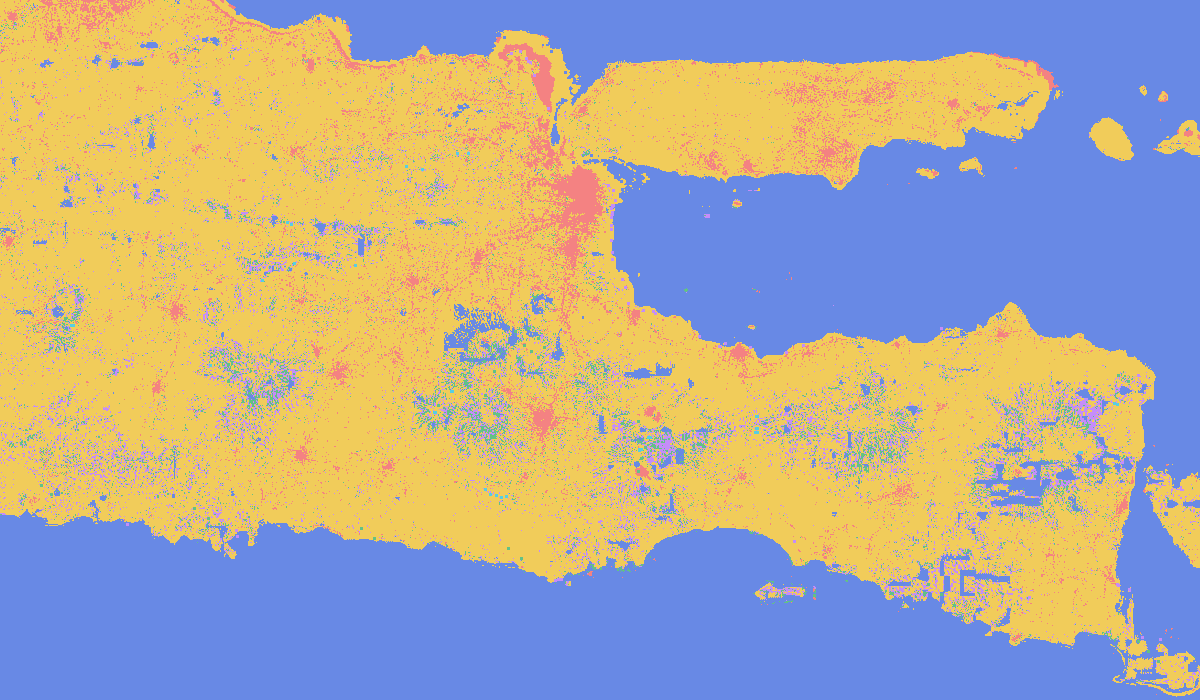
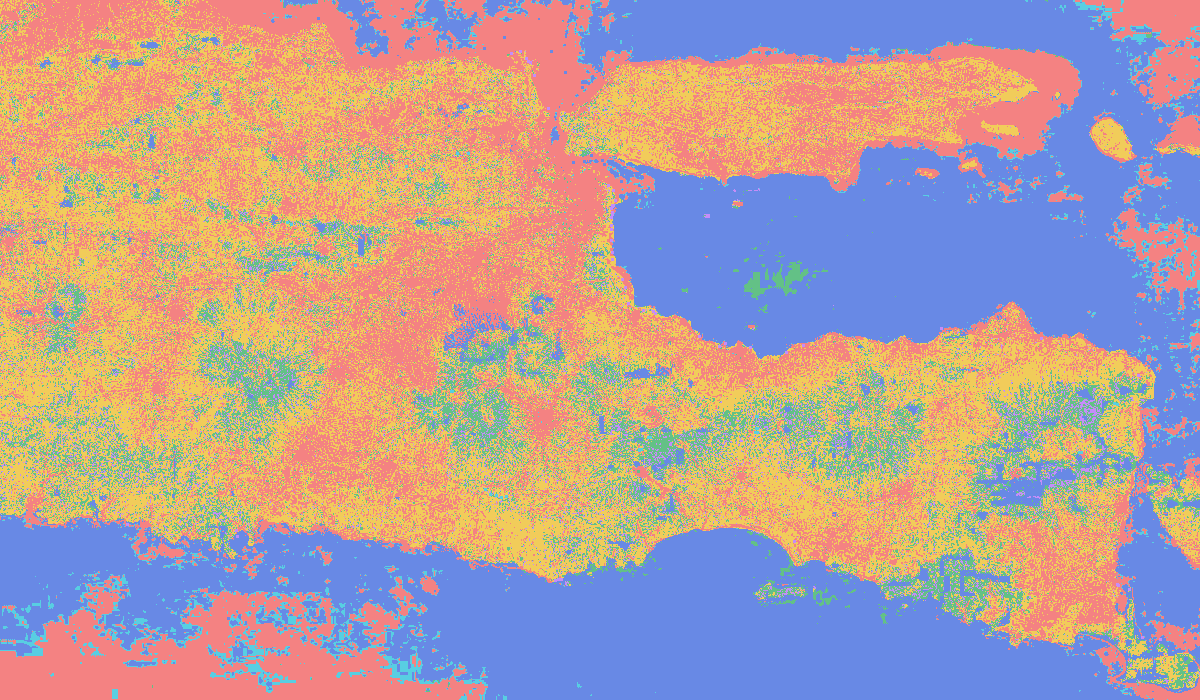
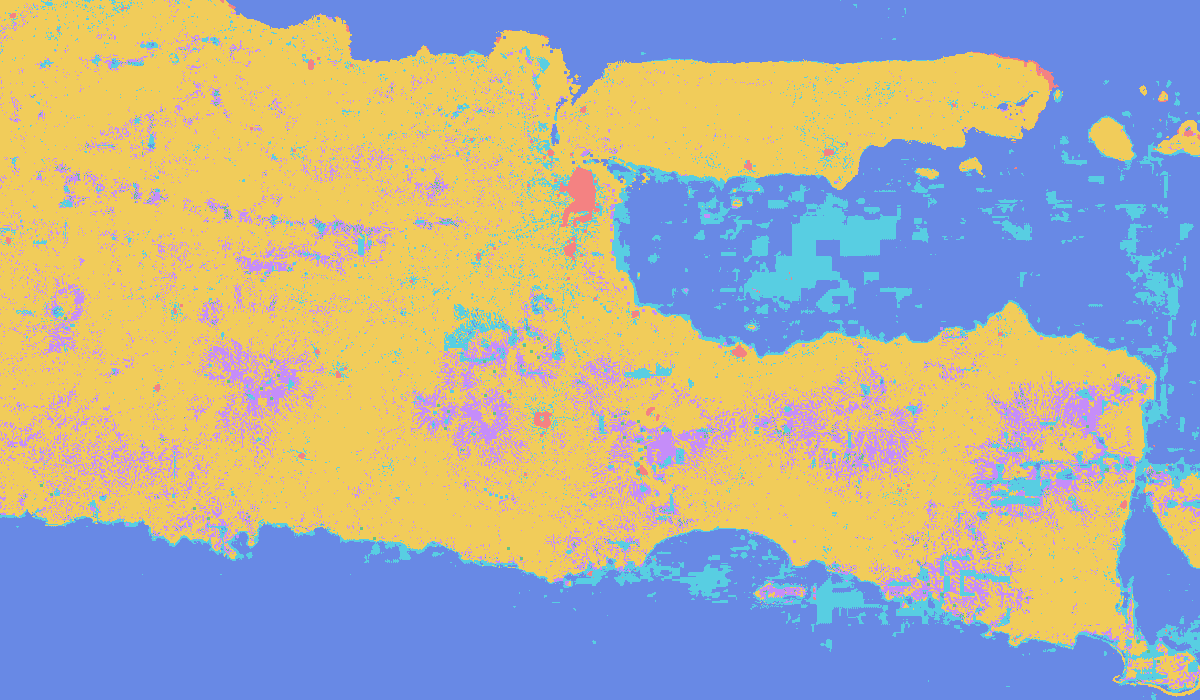
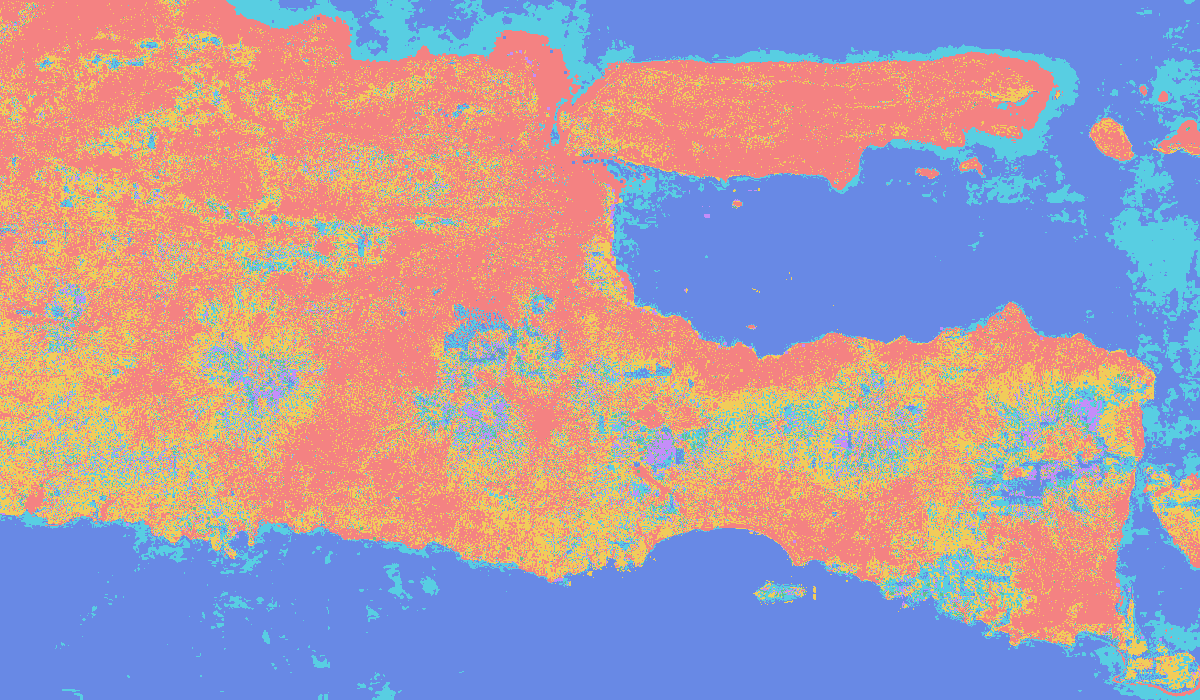

In [24]:
# =============================================================================
# LANGKAH 11: PEMBUATAN PETA INTERAKTIF FOLIUM DENGAN 4 LAYER OVERLAY MODEL ML
# =============================================================================
import io
import base64
from PIL import Image

DELTA = 0.00045  # Setengah bentang koordinat (~50 meter petak)
jatim_center = [-7.650, 112.500]
m_jatim = folium.Map(location=jatim_center, zoom_start=8, tiles=None)

# 1. Basemap Google Satellite
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google Satellite',
    name='Google Satellite (Murni)',
    overlay=False,
    control=True
).add_to(m_jatim)

# 2. Basemap Google Satellite Hybrid
folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google Hybrid',
    name='Google Hybrid (Satelit + Jalan)',
    overlay=False,
    control=True
).add_to(m_jatim)

# 3. Basemap OpenStreetMap
folium.TileLayer(
    tiles='OpenStreetMap',
    name='OpenStreetMap (Vektor)',
    overlay=False,
    control=True
).add_to(m_jatim)

# =============================================================================
# A. EMPAT (4) LAYER OVERLAY RASTER KLASIFIKASI MODEL MACHINE LEARNING
# =============================================================================
color_map_rgb = {
    1: [234, 179, 8],    # Sawah: Kuning
    2: [239, 68, 68],    # Bangunan: Merah
    3: [168, 85, 247],   # Mangrove: Ungu
    4: [22, 163, 74],    # Lahan Hijau: Hijau
    5: [29, 78, 216],    # Laut: Biru Dongker
    6: [6, 182, 212]     # Danau: Cyan
}

def create_raster_overlay(arr_data, opacity=170):
    h, w = arr_data.shape
    rgba = np.zeros((h, w, 4), dtype=np.uint8)
    for cid, col in color_map_rgb.items():
        mask = (arr_data == cid)
        rgba[mask, :3] = col
        rgba[mask, 3] = opacity
    buf = io.BytesIO()
    Image.fromarray(rgba).save(buf, format='PNG')
    return f"data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}"

# Overlay 1: Random Forest (Default Aktif)
folium.raster_layers.ImageOverlay(
    name="Overlay Raster: Random Forest (Default)",
    image=create_raster_overlay(cls_rf),
    bounds=[[cls_bounds.bottom, cls_bounds.left], [cls_bounds.top, cls_bounds.right]],
    opacity=0.70,
    interactive=True,
    show=True,
    zindex=1
).add_to(m_jatim)

# Overlay 2: XGBoost
folium.raster_layers.ImageOverlay(
    name="Overlay Raster: XGBoost",
    image=create_raster_overlay(cls_xgb),
    bounds=[[cls_bounds.bottom, cls_bounds.left], [cls_bounds.top, cls_bounds.right]],
    opacity=0.70,
    interactive=True,
    show=False,
    zindex=2
).add_to(m_jatim)

# Overlay 3: SVM (RBF)
folium.raster_layers.ImageOverlay(
    name="Overlay Raster: Support Vector Machine (SVM)",
    image=create_raster_overlay(cls_svm),
    bounds=[[cls_bounds.bottom, cls_bounds.left], [cls_bounds.top, cls_bounds.right]],
    opacity=0.70,
    interactive=True,
    show=False,
    zindex=3
).add_to(m_jatim)

# Overlay 4: Gradient Boosting
folium.raster_layers.ImageOverlay(
    name="Overlay Raster: Gradient Boosting",
    image=create_raster_overlay(cls_gb),
    bounds=[[cls_bounds.bottom, cls_bounds.left], [cls_bounds.top, cls_bounds.right]],
    opacity=0.70,
    interactive=True,
    show=False,
    zindex=4
).add_to(m_jatim)

# =============================================================================
# B. LAYER BATAS ADMINISTRASI JAWA TIMUR
# =============================================================================
batas_path = 'batas_jawa_timur.geojson'
if not os.path.exists(batas_path):
    batas_path = 'materi/batas_jawa_timur.geojson'

if os.path.exists(batas_path):
    with open(batas_path, encoding='utf-8') as f:
        batas_json = json.load(f)
    folium.GeoJson(
        batas_json,
        name="Batas Administrasi Jawa Timur",
        style_function=lambda x: {
            'color': '#f59e0b',
            'weight': 2.5,
            'dashArray': '6, 6',
            'fillColor': '#f59e0b',
            'fillOpacity': 0.04
        }
    ).add_to(m_jatim)

# =============================================================================
# C. FEATURE GROUPS PER KELAS GROUND TRUTH (KONTROL INDEPENDEN 6 KELAS)
# =============================================================================
fg_classes = {
    'Sawah': folium.FeatureGroup(name="Sawah (Kelas 1)"),
    'Bangunan': folium.FeatureGroup(name="Bangunan (Kelas 2)"),
    'Mangrove': folium.FeatureGroup(name="Mangrove (Kelas 3)"),
    'Lahan Hijau': folium.FeatureGroup(name="Lahan Hijau (Kelas 4)"),
    'Perairan Terbuka (Laut)': folium.FeatureGroup(name="Laut (Kelas 5)"),
    'Danau / Ranu-ranu': folium.FeatureGroup(name="Danau/Ranu (Kelas 6)")
}

fg_pred = folium.FeatureGroup(name="Titik Evaluasi Ground Truth (300 Sampel)")

# Evaluasi Prediksi pada 300 Sampel
y_pred_all = models['Random Forest'].predict(X)
df_dataset['pred_label'] = y_pred_all
df_dataset['is_match'] = (df_dataset['label'] == df_dataset['pred_label'])

for _, row in df_dataset.iterrows():
    s_id = row['id']
    lbl = row['label']
    p_lbl = row['pred_label']
    col_gt = class_colors[lbl]
    col_pred = class_colors[p_lbl]
    lat = row['lat']
    lon = row['lon']
    
    # 1. Petak Ground Truth (Poligon Realistis)
    popup_gt = f"""
    <div style="font-family: Arial; font-size: 12px; width: 230px;">
        <h4 style="margin:0 0 5px 0; color:{col_gt}; border-bottom: 2px solid {col_gt};">{lbl}</h4>
        <b>ID:</b> #{s_id} - {row['nama_lokasi']}<br>
        <b>Wilayah:</b> {row['kab_kota']}<br>
        <b>Kanal B04/B08:</b> {row['B04_Red']:.4f} / {row['B08_NIR']:.4f}<br>
        <b>NDVI:</b> {row['NDVI']:.4f} | <b>MNDWI:</b> {row['MNDWI']:.4f}<br>
        <b>Status:</b> Ground Truth SNI 7645-1:2014
    </div>
    """
    geom_match = gdf_samples.loc[gdf_samples['id'] == s_id, 'geometry']
    if len(geom_match) > 0 and geom_match.values[0].geom_type == 'Polygon':
        g_poly = geom_match.values[0]
        poly_coords = [[y, x] for x, y in g_poly.exterior.coords]
    else:
        poly_coords = [
            [lat - DELTA, lon - DELTA],
            [lat - DELTA, lon + DELTA],
            [lat + DELTA, lon + DELTA],
            [lat + DELTA, lon - DELTA]
        ]
    if lbl in fg_classes:
        folium.Polygon(poly_coords, color=col_gt, fill=True, fillColor=col_gt, fillOpacity=0.6,
                       popup=folium.Popup(popup_gt, max_width=260)).add_to(fg_classes[lbl])
                   
    # 2. Marker Prediksi Machine Learning
    is_match = row['is_match']
    popup_pred = f"""
    <div style="font-family: Arial; font-size: 12px; width: 230px;">
        <h4 style="margin:0 0 5px 0; color:{col_pred}; border-bottom: 2px solid {col_pred};">Prediksi: {p_lbl}</h4>
        <b>ID:</b> #{s_id} - {row['nama_lokasi']}<br>
        <b>Aktual:</b> {lbl}<br>
        <b>Status:</b> {'COCOK' if is_match else 'BEDA'}<br>
        <b>Model Evaluator:</b> Random Forest
    </div>
    """
    folium.CircleMarker([lat, lon], radius=6, color='white', weight=1.5, fill=True,
                        fillColor=col_pred, fillOpacity=1.0,
                        popup=folium.Popup(popup_pred, max_width=260)).add_to(fg_pred)

# Tambahkan semua FeatureGroup ke peta
for fg in fg_classes.values():
    fg.add_to(m_jatim)
fg_pred.add_to(m_jatim)

# Kontrol Layer
folium.LayerControl(position='topright', collapsed=False).add_to(m_jatim)
plugins.Fullscreen(position='topleft').add_to(m_jatim)

map_out_html = 'peta_klasifikasi_lulc_jawa_timur.html'
if os.path.basename(os.getcwd()) != 'materi' and os.path.exists('materi'):
    map_out_html = 'materi/peta_klasifikasi_lulc_jawa_timur.html'

m_jatim.save(map_out_html)
print(f"Peta Interaktif Folium Multi-Layer dengan 4 Overlay Model tersimpan di: {map_out_html}")
m_jatim



---
## Bab 11: Analisis Spasial, Kebijakan Tata Ruang & Panduan Buka di QGIS
### 11.1 Rekomendasi Kebijakan Tata Ruang Jawa Timur
1. **Pengendalian Alih Fungsi Sawah & Perlindungan LP2B (UU No. 41/2009):**
   Mempertahankan zona kuning keemasan persawahan produktif di sentra lumbung padi Lembah Kali Brantas (Jombang, Nganjuk, Mojokerto) dan Pantura (Lamongan, Bojonegoro) dari konversi kawasan industri perkotaan (*urban sprawl*).
2. **Restorasi Sabuk Hijau Mangrove Pesisir (RZWP-3-K):**
   Memperkuat zonasi kawasan lindung sabuk hijau (*green belt*) mangrove di muara Kali Porong (Sidoarjo), Wonorejo (Pamurbaya), dan Ujungpangkah (Gresik) untuk mencegah abrasi dan intrusi air laut.
3. **Preservasi Sempadan Danau Vulkanik (*Ranu*) & Waduk Strategis:**
   Menegakkan batas sempadan danau 50–100 meter dari titik pasang air tertinggi (PP No. 38 Tahun 2011) di kawasan Bromo Tengger Semeru (Ranu Kumbolo, Ranu Pani) dan waduk Karangkates/Selorejo.
---
### 11.2 Panduan Lengkap Membuka di Software QGIS
Seluruh artefak hasil analisis dapat dibuka langsung di aplikasi desktop **QGIS (Quantum GIS)**:
1. **Membuka Petak Sampel Vektor Shapefile:**
   * Ekstrak berkas `sampel_lulc_jawa_timur.zip`.
   * Tarik (*drag & drop*) file `sampel_lulc_jawa_timur.shp` ke jendela kerja QGIS.
   * QGIS otomatis membaca file gaya `sampel_lulc_jawa_timur.qml` sehingga seluruh 300 petak langsung berwarna kontras 6 kelas dan berlabel teks nama lokasi.
2. **Membuka Peta Klasifikasi Tutupan Lahan GeoTIFF:**
   * Tarik file `klasifikasi_lulc_jawa_timur.tif` ke dalam QGIS.
   * Karena file gaya `klasifikasi_lulc_jawa_timur.qml` berada di folder yang sama, QGIS akan otomatis merender legenda warna 6 kelas tutupan lahan.
3. **Membuka Citra Satelit Sentinel-2A Multi-Band:**
   * Tarik file `sentinel2_jawa_timur_composite.tif` ke dalam QGIS.
   * File gaya `sentinel2_jawa_timur_composite.qml` otomatis menampilkan citra dalam komposit Natural True Color RGB (Red=B04, Green=B03, Blue=B02).
### 11.3 Tautan Akses Aplikasi Web GIS Publik
* **Aplikasi Streamlit Cloud:** [https://dy-nm-psd.streamlit.app/](https://dy-nm-psd.streamlit.app/)
* **Fitur:** Peta Web GIS Google Hybrid, Overlay Raster Dinamis 4 Model ML (RF, XGBoost, SVM, GB), Analisis Kurva Spektral, dan Unduh Arsip Shapefile QGIS.
